In [ ]:
Practica Teachable machine


In [ ]:
<!DOCTYPE html>
<html lang="es">

<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <title>Clasificador de imágenes · Teachable Machine</title>
    <link rel="preconnect" href="https://fonts.googleapis.com">
    <link href="https://fonts.googleapis.com/css2?family=Bricolage+Grotesque:wght@400;600;800&display=swap"
        rel="stylesheet">
    <style>
        :root {
            --bg: #eef1f6;
            --panel: #ffffff;
            --ink: #1b2433;
            --muted: #5d6879;
            --line: #d5dbe6;
            --accent: #2f5bff;
            --accent-ink: #ffffff;
            --ok: #12805c;
            --warn: #b45309;
            --bar: #dfe6f5;
        }

        @media (prefers-color-scheme: dark) {
            :root {
                --bg: #12161f;
                --panel: #1b2230;
                --ink: #e8ecf4;
                --muted: #9aa5b8;
                --line: #2e3748;
                --accent: #7a98ff;
                --accent-ink: #0d1220;
                --ok: #4fd1a1;
                --warn: #f0a04b;
                --bar: #28324a;
            }
        }

        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            background: var(--bg);
            color: var(--ink);
            font-family: "Bricolage Grotesque", system-ui, -apple-system, "Segoe UI", sans-serif;
            line-height: 1.5;
        }

        header {
            padding: 28px 20px 8px;
            max-width: 1100px;
            margin: 0 auto;
        }

        h1 {
            margin: 0;
            font-size: clamp(1.7rem, 4vw, 2.6rem);
            font-weight: 800;
            letter-spacing: -0.02em;
        }

        header p {
            margin: 6px 0 0;
            color: var(--muted);
            max-width: 60ch;
        }

        main {
            max-width: 1100px;
            margin: 0 auto;
            padding: 16px 20px 40px;
            display: grid;
            gap: 20px;
            grid-template-columns: 1fr;
        }

        @media (min-width: 860px) {
            main {
                grid-template-columns: 5fr 6fr;
                align-items: start;
            }
        }

        section {
            background: var(--panel);
            border: 1px solid var(--line);
            border-radius: 14px;
            padding: 18px;
        }

        h2 {
            margin: 0 0 12px;
            font-size: 1.1rem;
            font-weight: 600;
        }

        .stack {
            display: grid;
            gap: 20px;
        }

        /* Visor */
        .viewer {
            aspect-ratio: 1 / 1;
            width: 100%;
            max-width: 420px;
            margin: 0 auto 14px;
            background: var(--bar);
            border-radius: 10px;
            overflow: hidden;
            display: grid;
            place-items: center;
            color: var(--muted);
            text-align: center;
            padding: 10px;
        }

        .viewer canvas,
        .viewer img {
            width: 100%;
            height: 100%;
            object-fit: cover;
            display: block;
        }

        .actions {
            display: flex;
            flex-wrap: wrap;
            gap: 10px;
        }

        button,
        .file-btn {
            font: inherit;
            font-weight: 600;
            cursor: pointer;
            border-radius: 9px;
            padding: 10px 16px;
            border: 1px solid var(--line);
            background: var(--panel);
            color: var(--ink);
        }

        button.primary {
            background: var(--accent);
            border-color: var(--accent);
            color: var(--accent-ink);
        }

        button:disabled {
            opacity: .45;
            cursor: not-allowed;
        }

        button:focus-visible,
        .file-btn:focus-within,
        input:focus-visible {
            outline: 3px solid var(--accent);
            outline-offset: 2px;
        }

        .file-btn input {
            position: absolute;
            opacity: 0;
            width: 1px;
            height: 1px;
        }

        .file-btn {
            position: relative;
            display: inline-block;
        }

        /* Mensaje de salida */
        .output {
            border-radius: 10px;
            padding: 14px 16px;
            font-size: 1.15rem;
            font-weight: 600;
            border: 1px solid var(--line);
            background: var(--bg);
            min-height: 3.4rem;
        }

        .output.match {
            border-color: var(--ok);
            color: var(--ok);
        }

        .output.nomatch {
            border-color: var(--warn);
            color: var(--warn);
        }

        /* Barras de probabilidad */
        .bars {
            display: grid;
            gap: 10px;
            margin-top: 14px;
        }

        .bar-row {
            display: grid;
            grid-template-columns: 1fr auto;
            gap: 2px 10px;
            font-size: .95rem;
        }

        .bar-track {
            grid-column: 1 / -1;
            height: 10px;
            background: var(--bar);
            border-radius: 99px;
            overflow: hidden;
        }

        .bar-fill {
            height: 100%;
            width: 0;
            background: var(--accent);
            transition: width .15s linear;
        }

        .bar-row.top .bar-fill {
            background: var(--ok);
        }

        /* Umbral y mensajes */
        .field {
            display: grid;
            gap: 6px;
            margin-bottom: 14px;
        }

        .field label {
            font-weight: 600;
        }

        input[type="range"] {
            width: 100%;
            accent-color: var(--accent);
        }

        input[type="text"] {
            font: inherit;
            padding: 8px 10px;
            border-radius: 8px;
            width: 100%;
            border: 1px solid var(--line);
            background: var(--bg);
            color: var(--ink);
        }

        .msg-row {
            display: grid;
            gap: 4px;
            margin-bottom: 10px;
        }

        .msg-row small {
            color: var(--muted);
        }

        /* Histórico */
        .history-head {
            display: flex;
            justify-content: space-between;
            align-items: center;
            gap: 10px;
        }

        .history-head h2 {
            margin: 0;
        }

        #history {
            list-style: none;
            margin: 12px 0 0;
            padding: 0;
            max-height: 260px;
            overflow-y: auto;
        }

        #history li {
            display: flex;
            flex-wrap: wrap;
            justify-content: space-between;
            gap: 4px 12px;
            padding: 8px 0;
            border-top: 1px solid var(--line);
            font-size: .95rem;
        }

        #history li:first-child {
            border-top: none;
        }

        #history .when {
            color: var(--muted);
        }

        .empty {
            color: var(--muted);
            margin: 12px 0 0;
        }

        .status {
            color: var(--muted);
            font-size: .9rem;
            margin-top: 10px;
            min-height: 1.3em;
        }

        @media (prefers-reduced-motion: reduce) {
            .bar-fill {
                transition: none;
            }
        }
    </style>
</head>

<body>

    <header>
        <h1>Clasificador de imágenes</h1>
        <p>Enciende la cámara o sube una foto y el modelo entrenado en Teachable Machine te dirá qué ve.</p>
    </header>

    <main>
        <!-- Columna izquierda: entrada -->
        <div class="stack">
            <section aria-labelledby="t-entrada">
                <h2 id="t-entrada">Entrada</h2>
                <div class="viewer" id="viewer">
                    <span id="viewer-placeholder">Pulsa «Iniciar» para usar la cámara o sube una imagen.</span>
                </div>
                <div class="actions">
                    <button type="button" class="primary" id="btn-start">Iniciar</button>
                    <button type="button" id="btn-stop" disabled>Parar</button>
                    <label class="file-btn">
                        Subir imagen
                        <input type="file" id="file-input" accept="image/*">
                    </label>
                </div>
                <div class="status" id="status" role="status" aria-live="polite"></div>
            </section>

            <section aria-labelledby="t-ajustes">
                <h2 id="t-ajustes">Ajustes</h2>
                <div class="field">
                    <label for="threshold">Valor mínimo de coincidencia: <span id="threshold-value">80</span>%</label>
                    <input type="range" id="threshold" min="0" max="100" step="1" value="80">
                </div>
                <div id="messages">
                    <p class="empty">Los mensajes personalizados aparecerán al cargar el modelo.</p>
                </div>
            </section>
        </div>

        <!-- Columna derecha: resultados -->
        <div class="stack">
            <section aria-labelledby="t-resultado">
                <h2 id="t-resultado">Resultado</h2>
                <div class="output" id="output" aria-live="polite">Esperando una imagen…</div>
                <div class="bars" id="bars"></div>
            </section>

            <section aria-labelledby="t-historico">
                <div class="history-head">
                    <h2 id="t-historico">Histórico</h2>
                    <button type="button" id="btn-clear">Borrar</button>
                </div>
                <ul id="history"></ul>
                <p class="empty" id="history-empty">Todavía no hay resultados guardados.</p>
            </section>
        </div>
    </main>

    <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@latest/dist/tf.min.js"></script>
    <script
        src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@latest/dist/teachablemachine-image.min.js"></script>
    <script>
        // Ruta de la carpeta con model.json, metadata.json y weights.bin
        const URL = "./my_model/";
        const HISTORY_KEY = "tm-historico";

        let model = null, webcam = null, rafId = null, running = false;
        let maxPredictions = 0, lastLogged = null;
        let history = [];
        const messages = {};   // className -> mensaje personalizado

        const $ = (id) => document.getElementById(id);
        const viewer = $("viewer"), output = $("output"), bars = $("bars");

        /* ---------- Modelo ---------- */
        async function loadModel() {
            if (model) return;
            setStatus("Cargando modelo…");
            model = await tmImage.load(URL + "model.json", URL + "metadata.json");
            maxPredictions = model.getTotalClasses();
            buildMessageInputs();
            buildBars();
            setStatus("");
        }

        function classNames() { return model.getClassLabels(); }

        function buildMessageInputs() {
            const box = $("messages");
            box.innerHTML = "";
            classNames().forEach((name) => {
                messages[name] = `¡Es ${name}!`;
                const row = document.createElement("div");
                row.className = "msg-row";
                const label = document.createElement("label");
                label.textContent = `Mensaje para «${name}»`;
                label.htmlFor = "msg-" + name;
                const input = document.createElement("input");
                input.type = "text"; input.id = "msg-" + name; input.value = messages[name];
                input.addEventListener("input", () => { messages[name] = input.value; });
                row.append(label, input);
                box.appendChild(row);
            });
        }

        function buildBars() {
            bars.innerHTML = "";
            classNames().forEach((name) => {
                const row = document.createElement("div");
                row.className = "bar-row";
                row.dataset.name = name;
                row.innerHTML = `<span>${name}</span><span class="pct">0%</span>
        <div class="bar-track"><div class="bar-fill"></div></div>`;
                bars.appendChild(row);
            });
        }

        /* ---------- Cámara ---------- */
        async function start() {
            try {
                $("btn-start").disabled = true;
                await loadModel();
                setStatus("Pidiendo acceso a la cámara…");
                webcam = new tmImage.Webcam(300, 300, true);
                await webcam.setup();
                await webcam.play();
                viewer.innerHTML = "";
                viewer.appendChild(webcam.canvas);
                running = true;
                $("btn-stop").disabled = false;
                setStatus("Cámara en marcha.");
                rafId = requestAnimationFrame(loop);
            } catch (e) {
                console.error(e);
                $("btn-start").disabled = false;
                setStatus("No se pudo iniciar: " + (e.message || e) +
                    ". Comprueba la carpeta del modelo, el permiso de cámara y que uses un servidor local.");
            }
        }

        function stop() {
            running = false;
            if (rafId) cancelAnimationFrame(rafId);
            if (webcam) { webcam.stop(); webcam = null; }
            viewer.innerHTML = '<span>Cámara detenida. Pulsa «Iniciar» para volver a usarla.</span>';
            $("btn-start").disabled = false;
            $("btn-stop").disabled = true;
            lastLogged = null;
            setStatus("");
        }

        async function loop() {
            if (!running) return;
            webcam.update();
            await predict(webcam.canvas, "Cámara");
            rafId = requestAnimationFrame(loop);
        }

        /* ---------- Predicción ---------- */
        async function predict(element, source) {
            const prediction = await model.predict(element);
            const threshold = Number($("threshold").value) / 100;

            let top = prediction[0];
            prediction.forEach((p) => { if (p.probability > top.probability) top = p; });

            prediction.forEach((p) => {
                const row = bars.querySelector(`[data-name="${CSS.escape(p.className)}"]`);
                if (!row) return;
                const pct = Math.round(p.probability * 100);
                row.querySelector(".pct").textContent = pct + "%";
                row.querySelector(".bar-fill").style.width = pct + "%";
                row.classList.toggle("top", p === top);
            });

            const pct = Math.round(top.probability * 100);
            if (top.probability >= threshold) {
                output.className = "output match";
                output.textContent = `${messages[top.className] || top.className} (${pct}%)`;
                // En cámara solo se guarda al cambiar de clase, para no llenar el histórico
                if (source !== "Cámara" || lastLogged !== top.className) {
                    addHistory(top.className, pct, source);
                }
                lastLogged = top.className;
            } else {
                output.className = "output nomatch";
                output.textContent = `Sin coincidencia: ninguna clase llega al ${Math.round(threshold * 100)}%.`;
                lastLogged = null;
            }
        }

        /* ---------- Subir imagen ---------- */
        $("file-input").addEventListener("change", async (ev) => {
            const file = ev.target.files[0];
            if (!file) return;
            try {
                if (running) stop();
                await loadModel();
                const img = new Image();
                img.alt = "Imagen subida";
                img.src = window.URL.createObjectURL(file);
                await img.decode();
                viewer.innerHTML = "";
                viewer.appendChild(img);
                await predict(img, "Imagen");
            } catch (e) {
                console.error(e);
                setStatus("No se pudo procesar la imagen: " + (e.message || e));
            }
            ev.target.value = "";
        });

        /* ---------- Histórico ---------- */
        function addHistory(name, pct, source) {
            history.unshift({ name, pct, source, time: new Date().toLocaleTimeString("es-ES") });
            history = history.slice(0, 100);
            saveHistory();
            renderHistory();
        }

        function renderHistory() {
            const list = $("history");
            list.innerHTML = "";
            history.forEach((h) => {
                const li = document.createElement("li");
                li.innerHTML = `<span><strong></strong> · ${h.pct}%</span><span class="when">${h.source} · ${h.time}</span>`;
                li.querySelector("strong").textContent = h.name;
                list.appendChild(li);
            });
            $("history-empty").hidden = history.length > 0;
        }

        function saveHistory() {
            try { localStorage.setItem(HISTORY_KEY, JSON.stringify(history)); } catch (e) { }
        }
        function loadHistory() {
            try { history = JSON.parse(localStorage.getItem(HISTORY_KEY)) || []; } catch (e) { history = []; }
        }

        /* ---------- Utilidades y eventos ---------- */
        function setStatus(text) { $("status").textContent = text; }

        $("threshold").addEventListener("input", (e) => { $("threshold-value").textContent = e.target.value; });
        $("btn-start").addEventListener("click", start);
        $("btn-stop").addEventListener("click", stop);
        $("btn-clear").addEventListener("click", () => { history = []; saveHistory(); renderHistory(); });

        loadHistory();
        renderHistory();
    </script>
</body>

</html>

In [ ]:
{
    "modelTopology": {
        "class_name": "Sequential",
        "config": {
            "name": "sequential_4",
            "layers": [
                {
                    "class_name": "Sequential",
                    "config": {
                        "name": "sequential_1",
                        "layers": [
                            {
                                "class_name": "Model",
                                "config": {
                                    "name": "model1",
                                    "layers": [
                                        {
                                            "name": "input_1",
                                            "class_name": "InputLayer",
                                            "config": {
                                                "batch_input_shape": [
                                                    null,
                                                    224,
                                                    224,
                                                    3
                                                ],
                                                "dtype": "float32",
                                                "sparse": false,
                                                "name": "input_1"
                                            },
                                            "inbound_nodes": []
                                        },
                                        {
                                            "name": "Conv1_pad",
                                            "class_name": "ZeroPadding2D",
                                            "config": {
                                                "padding": [
                                                    [
                                                        0,
                                                        1
                                                    ],
                                                    [
                                                        0,
                                                        1
                                                    ]
                                                ],
                                                "data_format": "channels_last",
                                                "name": "Conv1_pad",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "input_1",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "Conv1",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 16,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    2,
                                                    2
                                                ],
                                                "padding": "valid",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "Conv1",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "Conv1_pad",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "bn_Conv1",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "bn_Conv1",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "Conv1",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "Conv1_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "Conv1_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "bn_Conv1",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "expanded_conv_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "expanded_conv_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "Conv1_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "expanded_conv_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "expanded_conv_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "expanded_conv_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "expanded_conv_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "expanded_conv_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "expanded_conv_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "expanded_conv_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 8,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "expanded_conv_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "expanded_conv_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "expanded_conv_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "expanded_conv_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "expanded_conv_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 48,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_1_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "expanded_conv_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_1_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_1_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_pad",
                                            "class_name": "ZeroPadding2D",
                                            "config": {
                                                "padding": [
                                                    [
                                                        0,
                                                        1
                                                    ],
                                                    [
                                                        0,
                                                        1
                                                    ]
                                                ],
                                                "data_format": "channels_last",
                                                "name": "block_1_pad",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    2,
                                                    2
                                                ],
                                                "padding": "valid",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_1_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_pad",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_1_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_1_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 8,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_1_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_1_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_1_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 48,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_2_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_2_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_2_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_2_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_2_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_2_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 8,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_2_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_2_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_2_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_2_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_1_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_2_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 48,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_3_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_2_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_3_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_3_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_pad",
                                            "class_name": "ZeroPadding2D",
                                            "config": {
                                                "padding": [
                                                    [
                                                        0,
                                                        1
                                                    ],
                                                    [
                                                        0,
                                                        1
                                                    ]
                                                ],
                                                "data_format": "channels_last",
                                                "name": "block_3_pad",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    2,
                                                    2
                                                ],
                                                "padding": "valid",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_3_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_pad",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_3_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_3_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 16,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_3_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_3_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_3_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 96,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_4_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_4_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_4_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_4_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_4_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_4_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 16,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_4_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_4_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_4_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_4_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_3_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_4_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 96,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_5_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_5_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_5_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_5_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_5_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_5_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 16,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_5_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_5_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_5_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_5_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_4_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_5_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 96,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_6_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_5_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_6_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_6_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_pad",
                                            "class_name": "ZeroPadding2D",
                                            "config": {
                                                "padding": [
                                                    [
                                                        0,
                                                        1
                                                    ],
                                                    [
                                                        0,
                                                        1
                                                    ]
                                                ],
                                                "data_format": "channels_last",
                                                "name": "block_6_pad",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    2,
                                                    2
                                                ],
                                                "padding": "valid",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_6_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_pad",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_6_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_6_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 24,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_6_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_6_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_6_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 144,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_7_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_7_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_7_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_7_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_7_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_7_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 24,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_7_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_7_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_7_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_7_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_6_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_7_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 144,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_8_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_8_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_8_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_8_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_8_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_8_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 24,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_8_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_8_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_8_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_8_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_7_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_8_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 144,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_9_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_9_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_9_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_9_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_9_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_9_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 24,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_9_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_9_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_9_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_9_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_8_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_9_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 144,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_10_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_9_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_10_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_10_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_10_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_10_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_10_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 32,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_10_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_10_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_10_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 192,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_11_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_11_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_11_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_11_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_11_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_11_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 32,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_11_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_11_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_11_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_11_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_10_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_11_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 192,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_12_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_12_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_12_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_12_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_12_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_12_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 32,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_12_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_12_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_12_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_12_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_11_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_12_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 192,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_13_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_12_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_13_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_13_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_pad",
                                            "class_name": "ZeroPadding2D",
                                            "config": {
                                                "padding": [
                                                    [
                                                        0,
                                                        1
                                                    ],
                                                    [
                                                        0,
                                                        1
                                                    ]
                                                ],
                                                "data_format": "channels_last",
                                                "name": "block_13_pad",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    2,
                                                    2
                                                ],
                                                "padding": "valid",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_13_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_pad",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_13_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_13_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 56,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_13_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_13_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_13_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 336,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_14_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_14_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_14_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_14_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_14_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_14_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 56,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_14_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_14_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_14_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_14_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_13_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_14_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 336,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_15_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_15_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_15_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_15_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_15_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_15_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 56,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_15_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_15_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_15_add",
                                            "class_name": "Add",
                                            "config": {
                                                "name": "block_15_add",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_14_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ],
                                                    [
                                                        "block_15_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_expand",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 336,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_16_expand",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_15_add",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_expand_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_16_expand_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_expand",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_expand_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_16_expand_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_expand_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_depthwise",
                                            "class_name": "DepthwiseConv2D",
                                            "config": {
                                                "kernel_size": [
                                                    3,
                                                    3
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_16_depthwise",
                                                "trainable": true,
                                                "depth_multiplier": 1,
                                                "depthwise_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "depthwise_regularizer": null,
                                                "depthwise_constraint": null
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_expand_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_depthwise_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_16_depthwise_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_depthwise",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_depthwise_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "block_16_depthwise_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_depthwise_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_project",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 112,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "same",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "block_16_project",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_depthwise_relu",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "block_16_project_BN",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "block_16_project_BN",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_project",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "Conv_1",
                                            "class_name": "Conv2D",
                                            "config": {
                                                "filters": 1280,
                                                "kernel_initializer": {
                                                    "class_name": "VarianceScaling",
                                                    "config": {
                                                        "scale": 1,
                                                        "mode": "fan_avg",
                                                        "distribution": "uniform",
                                                        "seed": null
                                                    }
                                                },
                                                "kernel_regularizer": null,
                                                "kernel_constraint": null,
                                                "kernel_size": [
                                                    1,
                                                    1
                                                ],
                                                "strides": [
                                                    1,
                                                    1
                                                ],
                                                "padding": "valid",
                                                "data_format": "channels_last",
                                                "dilation_rate": [
                                                    1,
                                                    1
                                                ],
                                                "activation": "linear",
                                                "use_bias": false,
                                                "bias_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "bias_regularizer": null,
                                                "activity_regularizer": null,
                                                "bias_constraint": null,
                                                "name": "Conv_1",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "block_16_project_BN",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "Conv_1_bn",
                                            "class_name": "BatchNormalization",
                                            "config": {
                                                "axis": -1,
                                                "momentum": 0.999,
                                                "epsilon": 0.001,
                                                "center": true,
                                                "scale": true,
                                                "beta_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "gamma_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "moving_mean_initializer": {
                                                    "class_name": "Zeros",
                                                    "config": {}
                                                },
                                                "moving_variance_initializer": {
                                                    "class_name": "Ones",
                                                    "config": {}
                                                },
                                                "beta_regularizer": null,
                                                "gamma_regularizer": null,
                                                "beta_constraint": null,
                                                "gamma_constraint": null,
                                                "name": "Conv_1_bn",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "Conv_1",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        },
                                        {
                                            "name": "out_relu",
                                            "class_name": "ReLU",
                                            "config": {
                                                "max_value": 6,
                                                "name": "out_relu",
                                                "trainable": true
                                            },
                                            "inbound_nodes": [
                                                [
                                                    [
                                                        "Conv_1_bn",
                                                        0,
                                                        0,
                                                        {}
                                                    ]
                                                ]
                                            ]
                                        }
                                    ],
                                    "input_layers": [
                                        [
                                            "input_1",
                                            0,
                                            0
                                        ]
                                    ],
                                    "output_layers": [
                                        [
                                            "out_relu",
                                            0,
                                            0
                                        ]
                                    ]
                                }
                            },
                            {
                                "class_name": "GlobalAveragePooling2D",
                                "config": {
                                    "data_format": "channels_last",
                                    "name": "global_average_pooling2d_GlobalAveragePooling2D1",
                                    "trainable": true
                                }
                            }
                        ]
                    }
                },
                {
                    "class_name": "Sequential",
                    "config": {
                        "name": "sequential_3",
                        "layers": [
                            {
                                "class_name": "Dense",
                                "config": {
                                    "units": 100,
                                    "activation": "relu",
                                    "use_bias": true,
                                    "kernel_initializer": {
                                        "class_name": "VarianceScaling",
                                        "config": {
                                            "scale": 1,
                                            "mode": "fan_in",
                                            "distribution": "normal",
                                            "seed": null
                                        }
                                    },
                                    "bias_initializer": {
                                        "class_name": "Zeros",
                                        "config": {}
                                    },
                                    "kernel_regularizer": null,
                                    "bias_regularizer": null,
                                    "activity_regularizer": null,
                                    "kernel_constraint": null,
                                    "bias_constraint": null,
                                    "name": "dense_Dense1",
                                    "trainable": true,
                                    "batch_input_shape": [
                                        null,
                                        1280
                                    ],
                                    "dtype": "float32"
                                }
                            },
                            {
                                "class_name": "Dense",
                                "config": {
                                    "units": 2,
                                    "activation": "softmax",
                                    "use_bias": false,
                                    "kernel_initializer": {
                                        "class_name": "VarianceScaling",
                                        "config": {
                                            "scale": 1,
                                            "mode": "fan_in",
                                            "distribution": "normal",
                                            "seed": null
                                        }
                                    },
                                    "bias_initializer": {
                                        "class_name": "Zeros",
                                        "config": {}
                                    },
                                    "kernel_regularizer": null,
                                    "bias_regularizer": null,
                                    "activity_regularizer": null,
                                    "kernel_constraint": null,
                                    "bias_constraint": null,
                                    "name": "dense_Dense2",
                                    "trainable": true
                                }
                            }
                        ]
                    }
                }
            ]
        },
        "keras_version": "tfjs-layers 1.7.4",
        "backend": "tensor_flow.js"
    },
    "weightsManifest": [
        {
            "paths": [
                "weights.bin"
            ],
            "weights": [
                {
                    "name": "Conv1/kernel",
                    "shape": [
                        3,
                        3,
                        3,
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "bn_Conv1/gamma",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "bn_Conv1/beta",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        16,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_depthwise_BN/gamma",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_depthwise_BN/beta",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_project/kernel",
                    "shape": [
                        1,
                        1,
                        16,
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_project_BN/gamma",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_project_BN/beta",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_expand/kernel",
                    "shape": [
                        1,
                        1,
                        8,
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_expand_BN/gamma",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_expand_BN/beta",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        48,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_depthwise_BN/gamma",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_depthwise_BN/beta",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_project/kernel",
                    "shape": [
                        1,
                        1,
                        48,
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_project_BN/gamma",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_project_BN/beta",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_expand/kernel",
                    "shape": [
                        1,
                        1,
                        8,
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_expand_BN/gamma",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_expand_BN/beta",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        48,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_depthwise_BN/gamma",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_depthwise_BN/beta",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_project/kernel",
                    "shape": [
                        1,
                        1,
                        48,
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_project_BN/gamma",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_project_BN/beta",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_expand/kernel",
                    "shape": [
                        1,
                        1,
                        8,
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_expand_BN/gamma",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_expand_BN/beta",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        48,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_depthwise_BN/gamma",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_depthwise_BN/beta",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_project/kernel",
                    "shape": [
                        1,
                        1,
                        48,
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_project_BN/gamma",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_project_BN/beta",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_expand/kernel",
                    "shape": [
                        1,
                        1,
                        16,
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_expand_BN/gamma",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_expand_BN/beta",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        96,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_depthwise_BN/gamma",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_depthwise_BN/beta",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_project/kernel",
                    "shape": [
                        1,
                        1,
                        96,
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_project_BN/gamma",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_project_BN/beta",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_expand/kernel",
                    "shape": [
                        1,
                        1,
                        16,
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_expand_BN/gamma",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_expand_BN/beta",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        96,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_depthwise_BN/gamma",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_depthwise_BN/beta",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_project/kernel",
                    "shape": [
                        1,
                        1,
                        96,
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_project_BN/gamma",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_project_BN/beta",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_expand/kernel",
                    "shape": [
                        1,
                        1,
                        16,
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_expand_BN/gamma",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_expand_BN/beta",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        96,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_depthwise_BN/gamma",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_depthwise_BN/beta",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_project/kernel",
                    "shape": [
                        1,
                        1,
                        96,
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_project_BN/gamma",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_project_BN/beta",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_expand/kernel",
                    "shape": [
                        1,
                        1,
                        24,
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_expand_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_expand_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        144,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_depthwise_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_depthwise_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_project/kernel",
                    "shape": [
                        1,
                        1,
                        144,
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_project_BN/gamma",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_project_BN/beta",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_expand/kernel",
                    "shape": [
                        1,
                        1,
                        24,
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_expand_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_expand_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        144,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_depthwise_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_depthwise_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_project/kernel",
                    "shape": [
                        1,
                        1,
                        144,
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_project_BN/gamma",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_project_BN/beta",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_expand/kernel",
                    "shape": [
                        1,
                        1,
                        24,
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_expand_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_expand_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        144,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_depthwise_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_depthwise_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_project/kernel",
                    "shape": [
                        1,
                        1,
                        144,
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_project_BN/gamma",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_project_BN/beta",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_expand/kernel",
                    "shape": [
                        1,
                        1,
                        24,
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_expand_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_expand_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        144,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_depthwise_BN/gamma",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_depthwise_BN/beta",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_project/kernel",
                    "shape": [
                        1,
                        1,
                        144,
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_project_BN/gamma",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_project_BN/beta",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_expand/kernel",
                    "shape": [
                        1,
                        1,
                        32,
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_expand_BN/gamma",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_expand_BN/beta",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        192,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_depthwise_BN/gamma",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_depthwise_BN/beta",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_project/kernel",
                    "shape": [
                        1,
                        1,
                        192,
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_project_BN/gamma",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_project_BN/beta",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_expand/kernel",
                    "shape": [
                        1,
                        1,
                        32,
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_expand_BN/gamma",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_expand_BN/beta",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        192,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_depthwise_BN/gamma",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_depthwise_BN/beta",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_project/kernel",
                    "shape": [
                        1,
                        1,
                        192,
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_project_BN/gamma",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_project_BN/beta",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_expand/kernel",
                    "shape": [
                        1,
                        1,
                        32,
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_expand_BN/gamma",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_expand_BN/beta",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        192,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_depthwise_BN/gamma",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_depthwise_BN/beta",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_project/kernel",
                    "shape": [
                        1,
                        1,
                        192,
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_project_BN/gamma",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_project_BN/beta",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_expand/kernel",
                    "shape": [
                        1,
                        1,
                        56,
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_expand_BN/gamma",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_expand_BN/beta",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        336,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_depthwise_BN/gamma",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_depthwise_BN/beta",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_project/kernel",
                    "shape": [
                        1,
                        1,
                        336,
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_project_BN/gamma",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_project_BN/beta",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_expand/kernel",
                    "shape": [
                        1,
                        1,
                        56,
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_expand_BN/gamma",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_expand_BN/beta",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        336,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_depthwise_BN/gamma",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_depthwise_BN/beta",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_project/kernel",
                    "shape": [
                        1,
                        1,
                        336,
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_project_BN/gamma",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_project_BN/beta",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_expand/kernel",
                    "shape": [
                        1,
                        1,
                        56,
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_expand_BN/gamma",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_expand_BN/beta",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_depthwise/depthwise_kernel",
                    "shape": [
                        3,
                        3,
                        336,
                        1
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_depthwise_BN/gamma",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_depthwise_BN/beta",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_project/kernel",
                    "shape": [
                        1,
                        1,
                        336,
                        112
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_project_BN/gamma",
                    "shape": [
                        112
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_project_BN/beta",
                    "shape": [
                        112
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "Conv_1/kernel",
                    "shape": [
                        1,
                        1,
                        112,
                        1280
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "Conv_1_bn/gamma",
                    "shape": [
                        1280
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "Conv_1_bn/beta",
                    "shape": [
                        1280
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "dense_Dense1/kernel",
                    "shape": [
                        1280,
                        100
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "dense_Dense1/bias",
                    "shape": [
                        100
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "dense_Dense2/kernel",
                    "shape": [
                        100,
                        2
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "bn_Conv1/moving_mean",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "bn_Conv1/moving_variance",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_depthwise_BN/moving_mean",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_depthwise_BN/moving_variance",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_project_BN/moving_mean",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "expanded_conv_project_BN/moving_variance",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_expand_BN/moving_mean",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_expand_BN/moving_variance",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_depthwise_BN/moving_mean",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_depthwise_BN/moving_variance",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_project_BN/moving_mean",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_1_project_BN/moving_variance",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_expand_BN/moving_mean",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_expand_BN/moving_variance",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_depthwise_BN/moving_mean",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_depthwise_BN/moving_variance",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_project_BN/moving_mean",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_2_project_BN/moving_variance",
                    "shape": [
                        8
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_expand_BN/moving_mean",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_expand_BN/moving_variance",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_depthwise_BN/moving_mean",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_depthwise_BN/moving_variance",
                    "shape": [
                        48
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_project_BN/moving_mean",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_3_project_BN/moving_variance",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_expand_BN/moving_mean",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_expand_BN/moving_variance",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_depthwise_BN/moving_mean",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_depthwise_BN/moving_variance",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_project_BN/moving_mean",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_4_project_BN/moving_variance",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_expand_BN/moving_mean",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_expand_BN/moving_variance",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_depthwise_BN/moving_mean",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_depthwise_BN/moving_variance",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_project_BN/moving_mean",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_5_project_BN/moving_variance",
                    "shape": [
                        16
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_expand_BN/moving_mean",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_expand_BN/moving_variance",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_depthwise_BN/moving_mean",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_depthwise_BN/moving_variance",
                    "shape": [
                        96
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_project_BN/moving_mean",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_6_project_BN/moving_variance",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_expand_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_expand_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_depthwise_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_depthwise_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_project_BN/moving_mean",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_7_project_BN/moving_variance",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_expand_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_expand_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_depthwise_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_depthwise_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_project_BN/moving_mean",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_8_project_BN/moving_variance",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_expand_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_expand_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_depthwise_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_depthwise_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_project_BN/moving_mean",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_9_project_BN/moving_variance",
                    "shape": [
                        24
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_expand_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_expand_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_depthwise_BN/moving_mean",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_depthwise_BN/moving_variance",
                    "shape": [
                        144
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_project_BN/moving_mean",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_10_project_BN/moving_variance",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_expand_BN/moving_mean",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_expand_BN/moving_variance",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_depthwise_BN/moving_mean",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_depthwise_BN/moving_variance",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_project_BN/moving_mean",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_11_project_BN/moving_variance",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_expand_BN/moving_mean",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_expand_BN/moving_variance",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_depthwise_BN/moving_mean",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_depthwise_BN/moving_variance",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_project_BN/moving_mean",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_12_project_BN/moving_variance",
                    "shape": [
                        32
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_expand_BN/moving_mean",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_expand_BN/moving_variance",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_depthwise_BN/moving_mean",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_depthwise_BN/moving_variance",
                    "shape": [
                        192
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_project_BN/moving_mean",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_13_project_BN/moving_variance",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_expand_BN/moving_mean",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_expand_BN/moving_variance",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_depthwise_BN/moving_mean",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_depthwise_BN/moving_variance",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_project_BN/moving_mean",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_14_project_BN/moving_variance",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_expand_BN/moving_mean",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_expand_BN/moving_variance",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_depthwise_BN/moving_mean",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_depthwise_BN/moving_variance",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_project_BN/moving_mean",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_15_project_BN/moving_variance",
                    "shape": [
                        56
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_expand_BN/moving_mean",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_expand_BN/moving_variance",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_depthwise_BN/moving_mean",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_depthwise_BN/moving_variance",
                    "shape": [
                        336
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_project_BN/moving_mean",
                    "shape": [
                        112
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "block_16_project_BN/moving_variance",
                    "shape": [
                        112
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "Conv_1_bn/moving_mean",
                    "shape": [
                        1280
                    ],
                    "dtype": "float32"
                },
                {
                    "name": "Conv_1_bn/moving_variance",
                    "shape": [
                        1280
                    ],
                    "dtype": "float32"
                }
            ]
        }
    ]
}

In [ ]:
{
    "tfjsVersion": "1.7.4",
    "tmVersion": "2.4.17",
    "packageVersion": "0.8.4-alpha2",
    "packageName": "@teachablemachine/image",
    "timeStamp": "2026-10-06T14:17:23.451Z",
    "userMetadata": {},
    "modelName": "tm-my-image-model",
    "labels": [
        "Raton",
        "Teclado"
    ],
    "imageSize": 224
}

Práctica 1: Teachable Machine

1. Qué había que hacer

En esta práctica teníamos que entrenar un modelo que reconociera imágenes con Teachable Machine, exportarlo y usarlo en una página web en local. Después había que mejorar esa página con varias cosas: que se vea mejor y sea responsive, botones de inicio y parada, un mensaje personalizado, un valor mínimo de coincidencia, un histórico de resultados y poder subir una imagen para clasificarla.

2. Cómo entrené el modelo

Entré en la web de Teachable Machine, pulsé en Get Started y elegí un proyecto de imagen con modelo estándar. Me salían dos clases por defecto y las renombré como Ratón y Teclado, porque son dos objetos que tenía a mano.

Para cada clase usé 3 muestras de imágenes. Después pulsé en Train Model, esperé a que terminara y el modelo quedó como «Modelo preparado», que es lo que se ve en la captura.

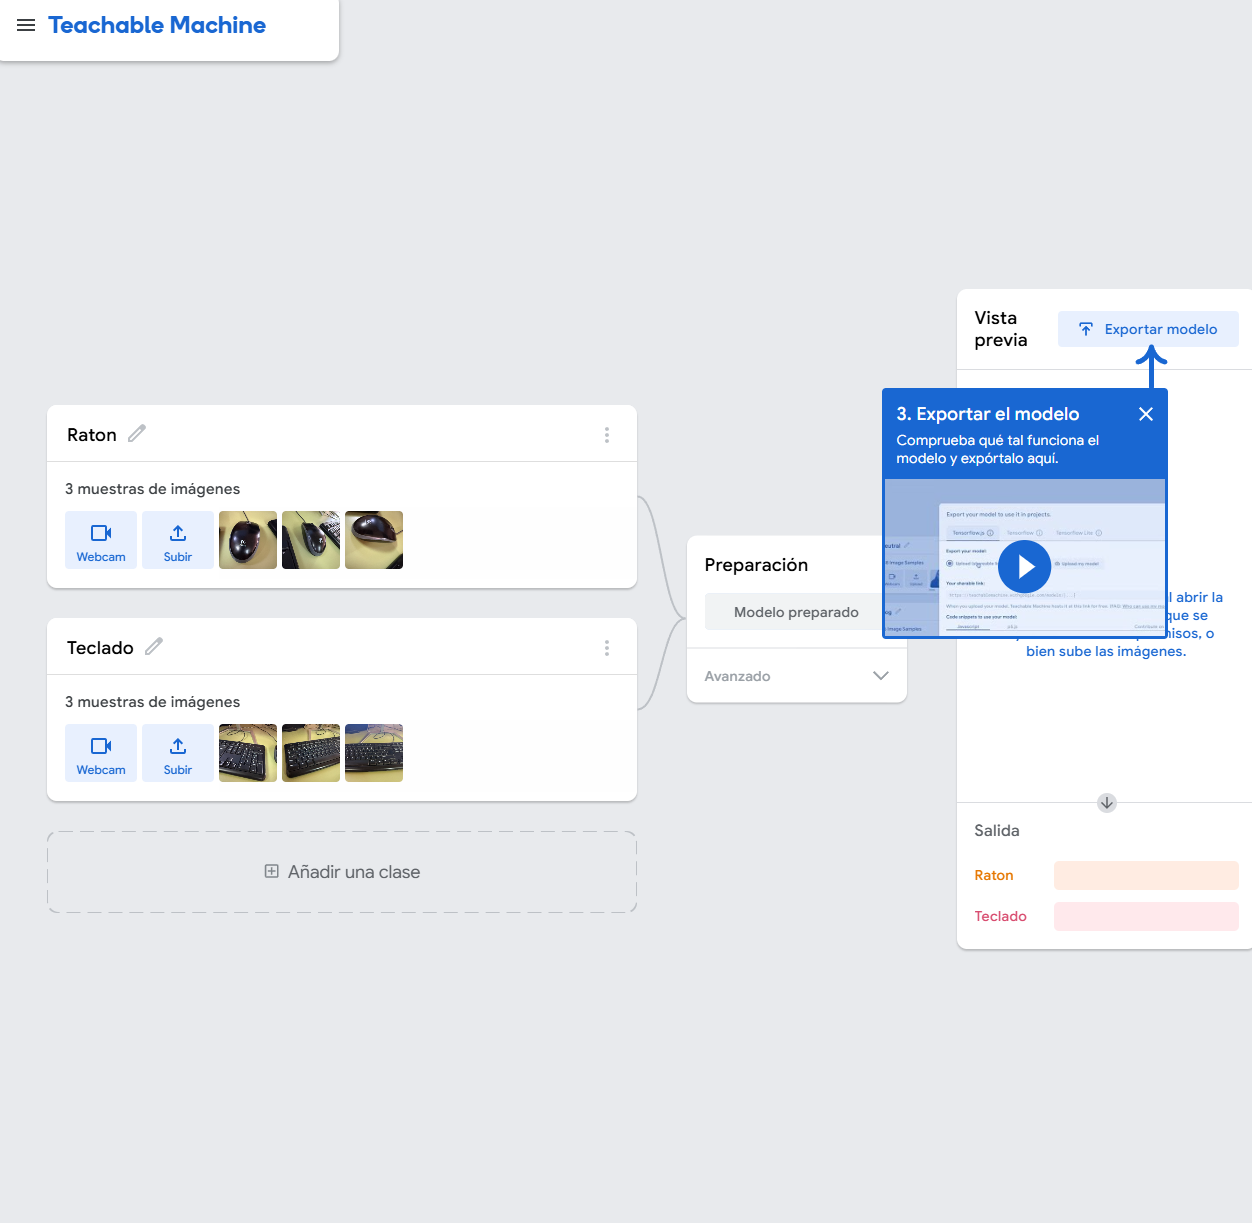

3. Cómo exporté el modelo

Una vez preparado el modelo pulsé en Exportar modelo y, en la pestaña de TensorFlow.js, descargué el modelo con la opción Download my model. Se descarga un zip con tres archivos:

model.json: describe la estructura del modelo.
weights.bin: guarda los pesos que ha aprendido.
metadata.json: contiene los nombres de las clases y datos del entrenamiento.

También exporté el modelo para TensorFlow (Keras), porque lo vamos a necesitar en una práctica más adelante, y guardé el proyecto de Teachable Machine por si hay que modificarlo.

4. Cómo preparé la carpeta del proyecto

Creé una carpeta llamada Proyecto con el archivo index.html y, al lado, una subcarpeta llamada my_model donde copié los tres archivos del modelo. Los tres tienen que estar juntos, porque model.json busca después weights.bin en su misma carpeta.

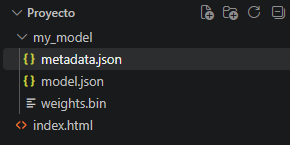

5. Cómo hice el index.html

Para empezar copié el código de ejemplo que da Teachable Machine en la opción de TensorFlow.js. Ese código usa dos librerías que se cargan desde internet: TensorFlow.js, que ejecuta el modelo en el navegador, y la librería de Teachable Machine para imágenes, que hace más fácil cargar el modelo y usar la cámara.

El código de ejemplo funciona así: la función init() carga el modelo con las rutas a model.json y metadata.json, activa la webcam y empieza un bucle que va cogiendo la imagen de la cámara y se la pasa a predict(). Esta función devuelve la probabilidad de cada clase y el código la escribe en pantalla.

Cuando comprobé que eso funcionaba, le fui añadiendo las mejoras que pedía el enunciado.

5.1 Diseño mejorado y responsive

Reorganicé la página en secciones (entrada, ajustes, resultado e histórico) y le puse estilos con CSS. Para que se adapte a cualquier pantalla usé una rejilla de dos columnas que en el móvil pasa a una sola, y el recuadro de la cámara se ajusta al ancho disponible. La página también cambia a modo oscuro o claro según la configuración del equipo.

5.2 Botones de inicio y parada

El botón Iniciar carga el modelo, enciende la cámara y empieza a predecir. El botón Parar detiene el bucle, apaga la cámara y deja otra vez disponible el botón de Iniciar.

5.3 Mensaje personalizado de salida

Al cargar el modelo se crea un campo de texto por cada clase, en la sección Ajustes, y lo que escribes ahí es el mensaje que sale cuando se detecta esa clase. Los nombres de las clases los coge solo del modelo, así que no hay que escribirlos a mano. En las capturas se ve el mensaje «¡Es Raton!» cuando enseño el ratón y el del teclado cuando enseño el teclado.

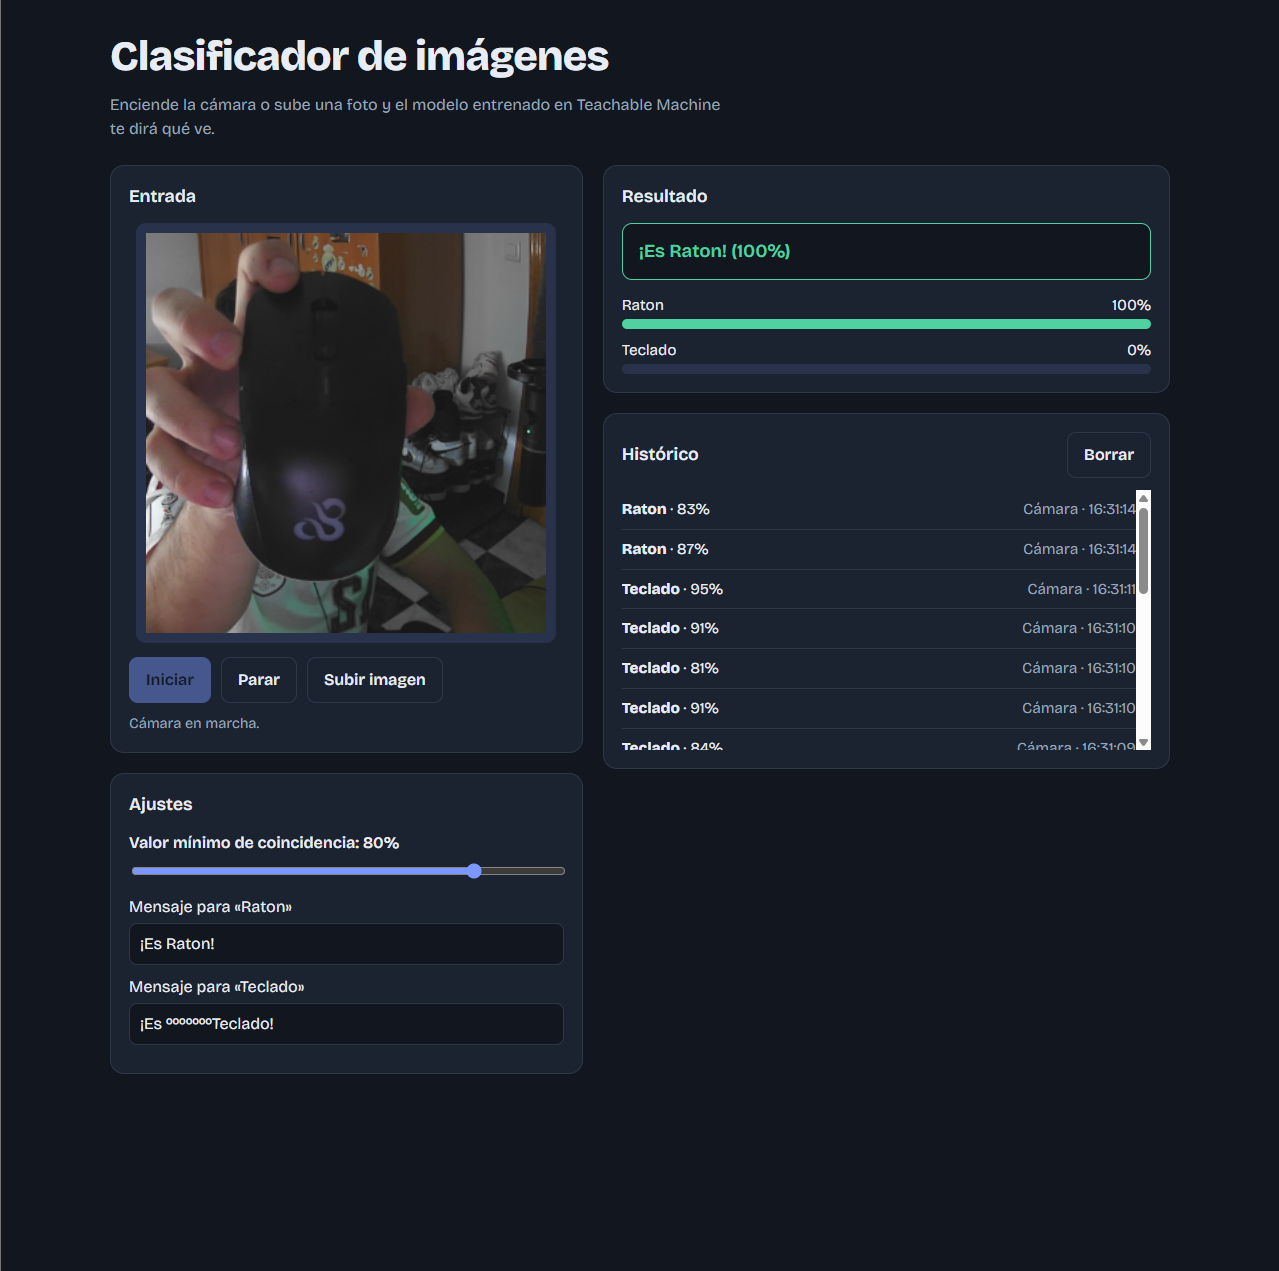

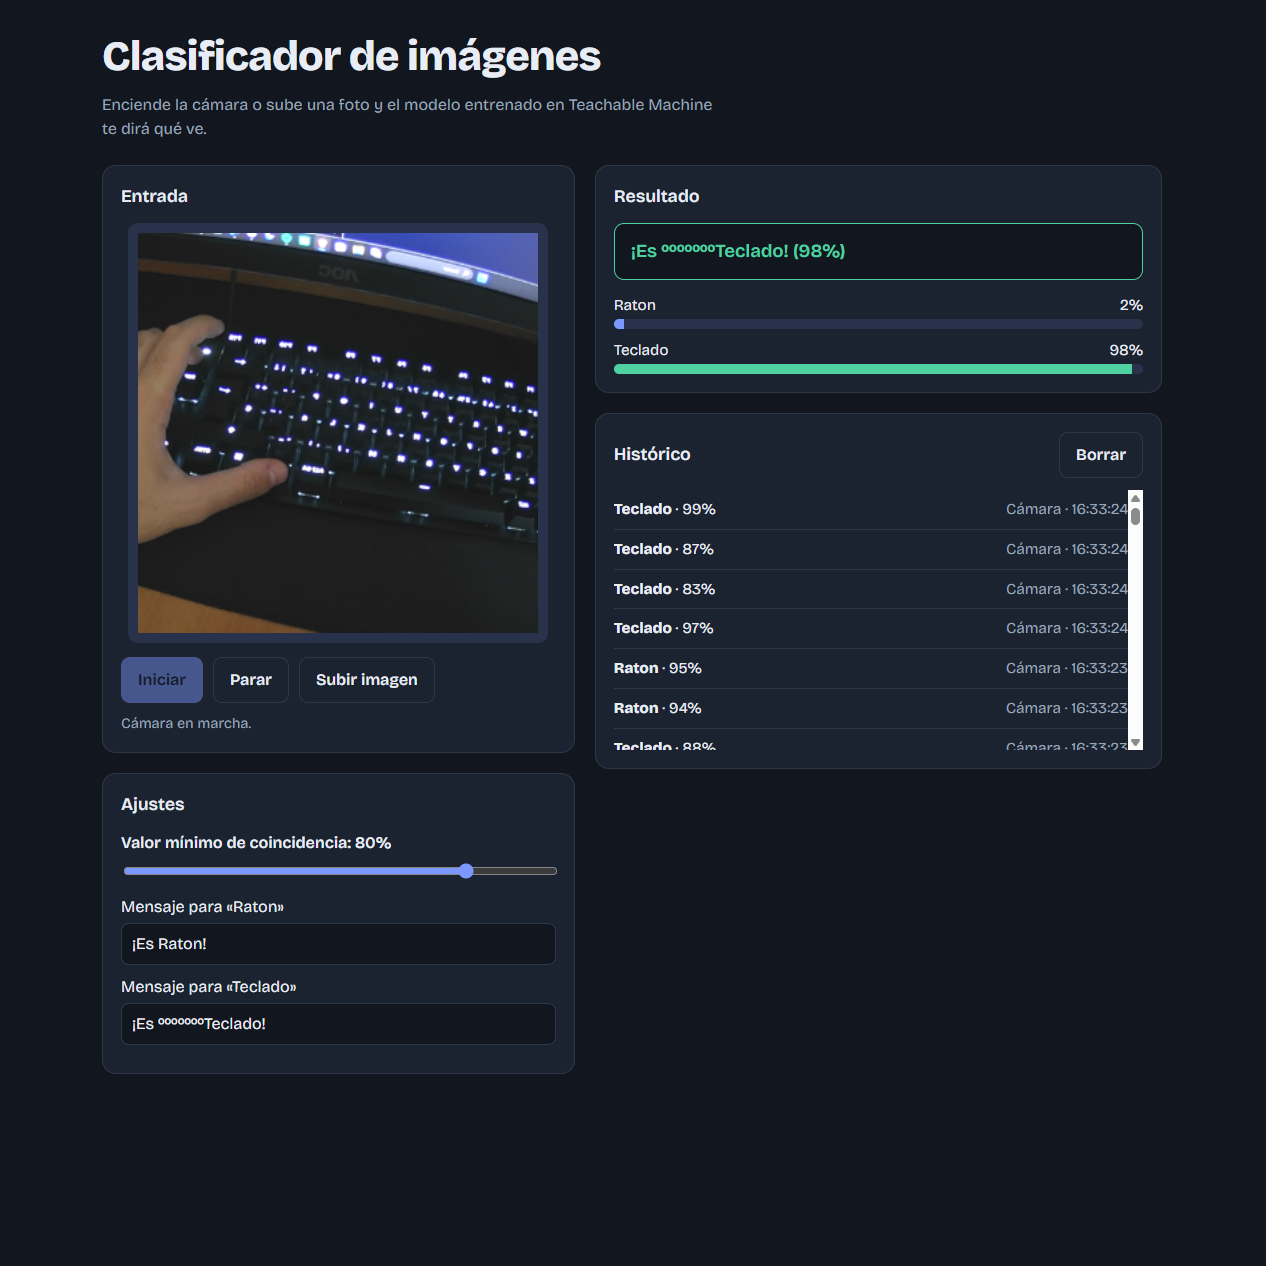

5.4 Valor mínimo de coincidencia

Añadí un deslizador de 0 a 100 en la sección Ajustes (en las capturas está en el 80 %). En cada predicción se mira qué clase tiene más probabilidad: si pasa del valor del deslizador se muestra su mensaje y, si no, sale «Sin coincidencia».

5.5 Histórico de resultados

Cada vez que se detecta algo se guarda en una lista con la clase, el porcentaje, si fue de la cámara o de una imagen, y la hora. Con la cámara solo se apunta cuando cambia la clase detectada, porque si no se llenaba la lista de repeticiones cada segundo. El histórico se guarda en el localStorage del navegador, así que no se pierde al recargar la página, y hay un botón Borrar para vaciarlo. Se puede ver en la parte derecha de las capturas del ratón y del teclado.

5.6 Subir una imagen para clasificarla

Puse un botón Subir imagen para elegir un archivo. Al elegirlo se apaga la cámara si estaba encendida y se le pasa la imagen al modelo, igual que se hacía con la cámara, así que el resultado y el histórico funcionan igual.

6. Cómo lo ejecuté en local

Al principio pensé que bastaba con hacer doble clic en el HTML, pero así no funciona, porque el navegador bloquea la carga del modelo y la cámara cuando abres el archivo directamente. Hay que usar un servidor local. Abrí una terminal en la carpeta del proyecto y ejecuté:

Después entré en http://localhost:8000 desde el navegador y pulsé en Iniciar.

7. Problema que tuve

Al darle a Iniciar me salió el error «Could not open your camera. You may have denied access». Como el mensaje salía después de cargar el modelo, me di cuenta de que el modelo estaba bien y que lo que fallaba era el permiso de la cámara.

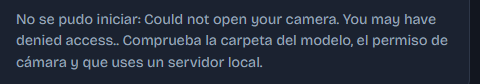

Lo solucioné dandole permisos para que pueda utilizar la camara, y después ya funcionó todo.